<a href="https://colab.research.google.com/github/KarthyV/finetuning_test/blob/main/realtime_sparsityFT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install -U transformers datasets accelerate peft trl bitsandbytes
import torch
print(torch.__version__, torch.cuda.is_available(), torch.cuda.get_device_name(0))

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.
2.14.1+cu130 True Tesla T4


In [2]:
from huggingface_hub import notebook_login
notebook_login()

In [3]:
from datasets import load_dataset
ds = load_dataset("Salesforce/xlam-function-calling-60k", split="train")
print(ds)
print(ds[0])

README.md:   0%|          | 0.00/10.7k [00:00<?, ?B/s]

xlam_function_calling_60k.json: reconstructing file:   0%|          |  0.00B / 96.1MB            

xlam_function_calling_60k.json: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/60000 [00:00<?, ? examples/s]

Dataset({
    features: ['id', 'query', 'answers', 'tools'],
    num_rows: 60000
})
{'id': 0, 'query': 'Where can I find live giveaways for beta access and games?', 'answers': '[{"name": "live_giveaways_by_type", "arguments": {"type": "beta"}}, {"name": "live_giveaways_by_type", "arguments": {"type": "game"}}]', 'tools': '[{"name": "live_giveaways_by_type", "description": "Retrieve live giveaways from the GamerPower API based on the specified type.", "parameters": {"type": {"description": "The type of giveaways to retrieve (e.g., game, loot, beta).", "type": "str", "default": "game"}}}]'}


In [4]:
ds = ds.shuffle(seed=42).select(range(2300))
train_ds = ds.select(range(2000))
test_ds  = ds.select(range(2000, 2300))

In [5]:
import json

SYSTEM = ('You are a function-calling assistant. Reply ONLY with a JSON list of '
          'tool calls, each like {"name": ..., "arguments": {...}}.')

def build_messages(ex):
    tools = json.loads(ex["tools"])
    user = f"Tools:\n{json.dumps(tools)}\n\nRequest: {ex['query']}"
    return [{"role": "system", "content": SYSTEM},
            {"role": "user", "content": user}]

def target_text(ex):
    return json.dumps(json.loads(ex["answers"]))

In [6]:
from transformers import AutoTokenizer
MODEL = "Qwen/Qwen2.5-0.5B-Instruct"
tok = AutoTokenizer.from_pretrained(MODEL)

ex = train_ds[0]
prompt = tok.apply_chat_template(build_messages(ex), tokenize=False,
                                 add_generation_prompt=True)
print(prompt + target_text(ex))

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

<|im_start|>system
You are a function-calling assistant. Reply ONLY with a JSON list of tool calls, each like {"name": ..., "arguments": {...}}.<|im_end|>
<|im_start|>user
Tools:
[{"name": "get_breed_information", "description": "Fetch information about a specific cat breed from the Cat Breeds API.", "parameters": {"breed": {"description": "The name of the cat breed to fetch information for.", "type": "str", "default": "aegean"}}}, {"name": "country_region_cities", "description": "Fetches a list of cities within a specified region of a given country from the GeoDB API.", "parameters": {"countryid": {"description": "An ISO-3166 country code or WikiData ID.", "type": "str", "default": "US"}, "regioncode": {"description": "An ISO-3166 or FIPS region code.", "type": "str", "default": "CA"}, "limit": {"description": "The maximum number of results to retrieve. Defaults to None.", "type": "int, optional", "default": ""}, "hateoasmode": {"description": "Include HATEOAS-style links in results. 

In [7]:
import numpy as np
lens = [len(tok(tok.apply_chat_template(build_messages(e), tokenize=False,
        add_generation_prompt=True) + target_text(e)).input_ids)
        for e in train_ds.select(range(300))]
print(np.percentile(lens, [50, 90, 99, 100]))

[ 382.5   711.3  1166.14 1361.  ]


In [8]:
def n_tokens(e):
    p = tok.apply_chat_template(build_messages(e), tokenize=False, add_generation_prompt=True)
    return len(tok(p + target_text(e)).input_ids)

MAX_LEN = 1024
train_ds = train_ds.filter(lambda e: n_tokens(e) <= MAX_LEN)
print(len(train_ds), "train examples kept")

Filter:   0%|          | 0/2000 [00:00<?, ? examples/s]

1961 train examples kept


In [9]:
import torch, time
from transformers import AutoModelForCausalLM

tok.padding_side = "left"
base_model = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.float16, device_map="cuda")
base_model.eval()

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(151936, 896)
    (layers): ModuleList(
      (0-23): 24 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear(in_features=896, out_features=896, bias=True)
          (k_proj): Linear(in_features=896, out_features=128, bias=True)
          (v_proj): Linear(in_features=896, out_features=128, bias=True)
          (o_proj): Linear(in_features=896, out_features=896, bias=False)
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear(in_features=896, out_features=4864, bias=False)
          (up_proj): Linear(in_features=896, out_features=4864, bias=False)
          (down_proj): Linear(in_features=4864, out_features=896, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): Qwen2RMSNorm((896,), eps=1e-06)
        (post_attention_layernorm): Qwen2RMSNorm((896,), eps=1e-06)
      )
    )
    (norm): Qwen2RMSNorm((896,), eps=1e-06)
    (rotary_emb): Qwen2

In [10]:
print(f"{sum(p.numel() for p in base_model.parameters())/1e6:.0f}M params")

494M params


In [11]:
test_list = list(test_ds)   # list of dicts, easy to slice

@torch.no_grad()
def generate(model, examples, batch_size=8, max_new_tokens=256):
    outs = []
    for i in range(0, len(examples), batch_size):
        batch = examples[i:i+batch_size]
        prompts = [tok.apply_chat_template(build_messages(e), tokenize=False,
                   add_generation_prompt=True) for e in batch]
        enc = tok(prompts, return_tensors="pt", padding=True).to(model.device)
        gen = model.generate(**enc, max_new_tokens=max_new_tokens,
                             do_sample=False, pad_token_id=tok.pad_token_id)
        new_tokens = gen[:, enc.input_ids.shape[1]:]
        outs += tok.batch_decode(new_tokens, skip_special_tokens=True)
    return outs

In [12]:
import re

def parse_calls(text):
    text = re.sub(r"^```(?:json)?|```$", "", text.strip()).strip()
    try: x = json.loads(text)
    except json.JSONDecodeError: return None, False
    is_list = isinstance(x, list)
    if isinstance(x, dict): x = [x]            # forgive a bare object, but remember it
    ok = isinstance(x, list) and all(isinstance(c, dict) for c in x)
    return (x if ok else None), is_list

def schema_ok(calls, tools):
    spec = {t["name"]: set(t["parameters"]) for t in tools}   # tool name -> allowed arg names
    return all(c.get("name") in spec
               and isinstance(c.get("arguments"), dict)
               and set(c["arguments"]) <= spec[c["name"]]
               for c in calls)

def canon(calls):
    return sorted(json.dumps(c, sort_keys=True) for c in calls)

def score(raws, examples):
    n = len(examples)
    m = dict(valid_json=0, list_format=0, schema_ok=0, exact=0)
    for raw, ex in zip(raws, examples):
        calls, is_list = parse_calls(raw)
        if calls is None: continue
        m["valid_json"] += 1
        m["list_format"] += is_list
        if schema_ok(calls, json.loads(ex["tools"])): m["schema_ok"] += 1
        if canon(calls) == canon(json.loads(ex["answers"])): m["exact"] += 1
    return {k: round(100 * v / n, 1) for k, v in m.items()}

In [13]:
def evaluate(model, examples, tag, max_new_tokens=256):
    torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    raws = generate(model, examples, max_new_tokens=max_new_tokens)
    secs = time.time() - t0
    metrics = score(raws, examples)
    metrics.update(peak_vram_gb=round(torch.cuda.max_memory_allocated() / 1e9, 2),
                   eval_secs=round(secs))
    json.dump({"metrics": metrics, "raw": raws}, open(f"results_{tag}.json", "w"))
    return metrics, raws

In [14]:
# 1) tiny run first: catch bugs in 1 minute, not 10
m, raws = evaluate(base_model, test_list[:16], "smoke")
print(m)
for r, e in list(zip(raws, test_list))[:3]:
    print("GOLD:", e["answers"]); print("PRED:", r); print("-" * 40)

{'valid_json': 75.0, 'list_format': 12.5, 'schema_ok': 56.2, 'exact': 25.0, 'peak_vram_gb': 1.36, 'eval_secs': 15}
GOLD: [{"name": "get_ip_zipcode", "arguments": {"ip": "208.80.152.201"}}]
PRED: {"name": "get_ip_zipcode", "arguments": {"ip": "208.80.152.201"}}
----------------------------------------
GOLD: [{"name": "nhl_score_board", "arguments": {"day": "15", "year": "2022", "month": "01"}}]
PRED: {"name": "nhl_score_board", "arguments": {"day": "15", "year": "2022", "month": "01", "limit": "5"}}
----------------------------------------
GOLD: [{"name": "v1_mortgagecalculator", "arguments": {"interest_rate": 4.5, "downpayment": 70000, "home_value": 350000, "duration_years": 15, "annual_home_insurance": 1500}}]
PRED: {"name": "v1_mortgagecalculator", "arguments": {"home_value": 350000, "downpayment": 70000, "annual_interest_rate": 4.5, "annual_home_insurance": 1500, "duration_years": 15}}
----------------------------------------


In [15]:
# 2) full baseline = Experiment A
m, raws = evaluate(base_model, test_list, "A_base_zeroshot")
print(m)

{'valid_json': 61.0, 'list_format': 12.3, 'schema_ok': 54.0, 'exact': 29.3, 'peak_vram_gb': 1.49, 'eval_secs': 192}


In [16]:
print(raws)

['{"name": "get_ip_zipcode", "arguments": {"ip": "208.80.152.201"}}', '{"name": "nhl_score_board", "arguments": {"day": "15", "year": "2022", "month": "01", "limit": "5"}}', '{"name": "v1_mortgagecalculator", "arguments": {"home_value": 350000, "downpayment": 70000, "annual_interest_rate": 4.5, "annual_home_insurance": 1500, "duration_years": 15}}', '[\n    {\n        "name": "baseball_league_rankings",\n        "arguments": {\n            "league_id": "MLB"\n        }\n    },\n    {\n        "name": "baseball_league_rankings",\n        "arguments": {\n            "league_id": "NPB"\n        }\n    }\n]', '[{"name": "get_models", "arguments": {"model_type": "image_recognition"}}] [{"name": "keywords", "arguments": {"content_type": "application/json", "text": "Christmas is one of the most widely celebrated holidays in the world. It is a time of joy, love, and giving, and is traditionally celebrated on December 25th every year. The holiday has its roots in Christianity, where it commemor

In [17]:
print(score(raws, test_list))

{'valid_json': 61.0, 'list_format': 12.3, 'schema_ok': 54.0, 'exact': 29.3}


In [18]:
####QLORA

In [19]:
import gc
del base_model; gc.collect(); torch.cuda.empty_cache()

val_raw   = train_ds.select(range(100))                   # small validation set
train_raw = train_ds.select(range(100, len(train_ds)))

def to_pc(ex):
    return {"prompt": build_messages(ex),
            "completion": [{"role": "assistant", "content": target_text(ex)}]}

train_pc = train_raw.map(to_pc, remove_columns=train_raw.column_names)
val_pc   = val_raw.map(to_pc,   remove_columns=val_raw.column_names)
print(train_pc[0]["completion"])

Map:   0%|          | 0/1861 [00:00<?, ? examples/s]

Map:   0%|          | 0/100 [00:00<?, ? examples/s]

[{'role': 'assistant', 'content': '[{"name": "get_coin_modifiers", "arguments": {"uuid": "coin_uuid123", "limit": 100}}]'}]


In [20]:
from transformers import BitsAndBytesConfig
from peft import prepare_model_for_kbit_training, LoraConfig

bnb = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16,
)
model = AutoModelForCausalLM.from_pretrained(
    MODEL, quantization_config=bnb, dtype=torch.float16, device_map="cuda")
model = prepare_model_for_kbit_training(model)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3195: FutureWarning: `gradient_checkpointing_enable` is deprecated and will be removed in v6. Use `activation_checkpointing_enable` instead.
  warnings.warn(


In [21]:
lora_cfg = LoraConfig(
    r=16, lora_alpha=32, lora_dropout=0.05, bias="none",
    task_type="CAUSAL_LM",
    target_modules="all-linear",
)

In [22]:
from trl import SFTConfig, SFTTrainer

tok.padding_side = "right"        # training pads on the right; we switch back to left for generation

cfg = SFTConfig(
    output_dir="out_B_qlora",
    num_train_epochs=1,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,       # effective batch = 16
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=10,
    max_length=1024,
    optim="paged_adamw_8bit",
    fp16=False,
    bf16=False,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    logging_steps=10,
    eval_strategy="steps", eval_steps=40,
    per_device_eval_batch_size=4,
    save_strategy="no",
    report_to="none",
)

trainer = SFTTrainer(model=model, args=cfg, train_dataset=train_pc,
                     eval_dataset=val_pc, processing_class=tok, peft_config=lora_cfg)
trainer.model.print_trainable_parameters()

/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1541: FutureWarning: `gradient_checkpointing` is deprecated and will be removed in v6. Use `activation_checkpointing` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)
/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1541: FutureWarning: `gradient_checkpointing_kwargs` is deprecated and will be removed in v6. Use `activation_checkpointing_kwargs` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


Tokenizing train dataset:   0%|          | 0/1861 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/1861 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/1861 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/1861 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497


In [23]:
torch.cuda.reset_peak_memory_stats()
t0 = time.time()
trainer.train()
print("train secs:", round(time.time() - t0),
      "| peak VRAM GB:", round(torch.cuda.max_memory_allocated() / 1e9, 2))

trainer.model.save_pretrained("adapter_B_qlora")

Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
40,0.044371,0.051555,0.047953,0.985606,276446.000000
80,0.048051,0.047860,0.044213,0.986842,535407.000000
117,0.058081,0.046383,0.043236,0.987182,788282.000000


train secs: 823 | peak VRAM GB: 2.77


In [33]:
from peft import PeftModel

tok.padding_side = "left"

base4 = AutoModelForCausalLM.from_pretrained(
    MODEL, quantization_config=bnb, dtype=torch.float16, device_map="cuda")
qlora_model = PeftModel.from_pretrained(base4, "adapter_B_qlora")
qlora_model.eval()

m, raws_B = evaluate(qlora_model, test_list, "B_qlora")
print(m)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


{'valid_json': 99.7, 'list_format': 99.7, 'schema_ok': 96.7, 'exact': 63.0, 'peak_vram_gb': 6.06, 'eval_secs': 416}


In [34]:
print(base4)

Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(151936, 896)
    (layers): ModuleList(
      (0-23): 24 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): lora.Linear4bit(
            (base_layer): Linear4bit(in_features=896, out_features=896, bias=True)
            (lora_dropout): ModuleDict(
              (default): Dropout(p=0.05, inplace=False)
            )
            (lora_A): ModuleDict(
              (default): Linear(in_features=896, out_features=16, bias=False)
            )
            (lora_B): ModuleDict(
              (default): Linear(in_features=16, out_features=896, bias=False)
            )
            (lora_embedding_A): ParameterDict()
            (lora_embedding_B): ParameterDict()
            (lora_magnitude_vector): ModuleDict()
          )
          (k_proj): lora.Linear4bit(
            (base_layer): Linear4bit(in_features=896, out_features=128, bias=True)
            (lora_dropout): ModuleDict(
              (

In [39]:
import math, torch.nn as nn

# del qlora_model, base4; gc.collect(); torch.cuda.empty_cache()

def load_fp16():
    m = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.float16, device_map="cuda").eval()
    for p in m.parameters():
        p.requires_grad_(False)     # no gradient tracking, so in-place edits are allowed
    return m

def prunable_linears(model):
    return {n: m for n, m in model.model.layers.named_modules() if isinstance(m, nn.Linear)}

def sparsity(model):
    z = t = 0
    for m in prunable_linears(model).values():
        z += (m.weight == 0).sum().item(); t += m.weight.numel()
    return 100 * z / t

@torch.no_grad()
def perplexity(model, texts, max_len=512):
    nll = n = 0
    for t in texts:
        enc = tok(t, return_tensors="pt", truncation=True, max_length=max_len).to(model.device)
        loss = model(**enc, labels=enc.input_ids).loss.item()
        k = enc.input_ids.shape[1] - 1
        nll += loss * k; n += k
    return math.exp(min(nll / n, 30))
def prune_magnitude(model, sp):
    with torch.no_grad():
        for m in prunable_linears(model).values():
            W = m.weight
            k = int(W.numel() * sp)
            thresh = W.abs().flatten().float().kthvalue(k).values
            W[W.abs() <= thresh] = 0

@torch.no_grad()
def collect_act_norms(model, texts):
    sumsq, hooks = {}, []
    def make_hook(name):
        def hook(mod, inp, out):
            x = inp[0].float()
            sumsq[name] = sumsq.get(name, 0) + x.pow(2).sum(dim=(0, 1))
        return hook
    for n, m in prunable_linears(model).items():
        hooks.append(m.register_forward_hook(make_hook(n)))
    for t in texts:
        enc = tok(t, return_tensors="pt", truncation=True, max_length=512).to(model.device)
        model(**enc)
    for h in hooks: h.remove()
    return {n: v.sqrt() for n, v in sumsq.items()}

@torch.no_grad()
def prune_wanda(model, act_norms, sp):
    for n, m in prunable_linears(model).items():
        W = m.weight
        score = W.abs().float() * act_norms[n].unsqueeze(0)
        k = int(W.shape[1] * sp)
        idx = torch.topk(score, k, dim=1, largest=False).indices
        mask = torch.ones_like(W, dtype=torch.bool)
        mask.scatter_(1, idx, False)
        W[~mask] = 0

In [40]:
calib_texts = [tok.apply_chat_template(build_messages(e), tokenize=False, add_generation_prompt=True)
               + target_text(e) for e in train_raw.select(range(128))]
ppl_texts = [tok.apply_chat_template(build_messages(e), tokenize=False, add_generation_prompt=True)
             + target_text(e) for e in val_raw.select(range(64))]

dense = load_fp16()
print("fp16 dense footprint GB:", round(dense.get_memory_footprint() / 1e9, 2))
act_norms = collect_act_norms(dense, calib_texts)
ppl_dense = perplexity(dense, ppl_texts)
print("dense perplexity:", round(ppl_dense, 2))
del dense; gc.collect(); torch.cuda.empty_cache()

sweep = {}
for sp in [0.3, 0.5, 0.7]:
    for name in ["magnitude", "wanda"]:
        m = load_fp16()
        prune_magnitude(m, sp) if name == "magnitude" else prune_wanda(m, act_norms, sp)
        sweep[(name, sp)] = (round(sparsity(m), 1), round(perplexity(m, ppl_texts), 2))
        print(name, sp, sweep[(name, sp)])
        del m; gc.collect(); torch.cuda.empty_cache()

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

fp16 dense footprint GB: 0.99
dense perplexity: 8.71


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

magnitude 0.3 (30.1, 9.29)


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

wanda 0.3 (29.9, 9.64)


... (4 outputs left out)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

magnitude 0.7 (70.2, 406449.65)


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

wanda 0.7 (70.0, 53.23)


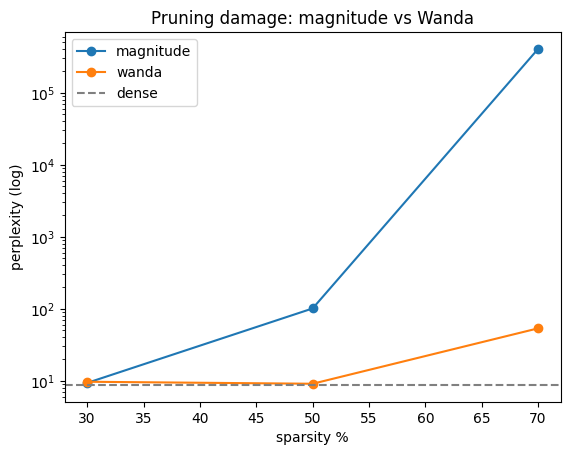

In [41]:
import matplotlib.pyplot as plt
for name in ["magnitude", "wanda"]:
    xs = [0.3, 0.5, 0.7]; ys = [sweep[(name, s)][1] for s in xs]
    plt.plot([x * 100 for x in xs], ys, marker="o", label=name)
plt.axhline(ppl_dense, color="gray", ls="--", label="dense")
plt.yscale("log"); plt.xlabel("sparsity %"); plt.ylabel("perplexity (log)"); plt.legend()
plt.title("Pruning damage: magnitude vs Wanda"); plt.show()

In [42]:
pruned = load_fp16()
prune_wanda(pruned, act_norms, 0.5)
print("sparsity %:", round(sparsity(pruned), 1))

m, raws_C = evaluate(pruned, test_list, "C_wanda50_zeroshot")
print(m)

pruned.save_pretrained("pruned_wanda50"); tok.save_pretrained("pruned_wanda50")
!du -sh pruned_wanda50

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

sparsity %: 50.0
{'valid_json': 29.7, 'list_format': 0.0, 'schema_ok': 11.7, 'exact': 3.0, 'peak_vram_gb': 3.25, 'eval_secs': 299}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

954M	pruned_wanda50


In [43]:
del pruned; gc.collect(); torch.cuda.empty_cache()

model = AutoModelForCausalLM.from_pretrained("pruned_wanda50", dtype=torch.float32, device_map="cuda")
print("sparsity before training %:", round(sparsity(model), 2))

zero_masks = {n: (p == 0) for n, p in model.named_parameters()
              if ".layers." in n and p.dim() == 2}
print(len(zero_masks), "masked matrices")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

sparsity before training %: 50.0
168 masked matrices


In [44]:
from transformers import TrainerCallback

class KeepMask(TrainerCallback):
    def __init__(self, zero_masks): self.zero_masks = zero_masks
    def on_step_end(self, args, state, control, model=None, **kwargs):
        with torch.no_grad():
            for n, p in model.named_parameters():
                if n in self.zero_masks:
                    p.masked_fill_(self.zero_masks[n], 0)

tok.padding_side = "right"
cfg_D = SFTConfig(
    output_dir="out_D_sparse_ft", num_train_epochs=1,
    per_device_train_batch_size=4, gradient_accumulation_steps=4,
    learning_rate=2e-5, lr_scheduler_type="cosine", warmup_steps=10,
    max_length=1024, optim="paged_adamw_8bit", fp16=True,
    gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False},
    logging_steps=10, eval_strategy="steps", eval_steps=40, per_device_eval_batch_size=4,
    save_strategy="no", report_to="none",
)
trainer = SFTTrainer(model=model, args=cfg_D, train_dataset=train_pc, eval_dataset=val_pc,
                     processing_class=tok, callbacks=[KeepMask(zero_masks)])

/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1541: FutureWarning: `gradient_checkpointing` is deprecated and will be removed in v6. Use `activation_checkpointing` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)
/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1541: FutureWarning: `gradient_checkpointing_kwargs` is deprecated and will be removed in v6. Use `activation_checkpointing_kwargs` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)


In [45]:
torch.cuda.reset_peak_memory_stats()
t0 = time.time()
trainer.train()
print("train secs:", round(time.time() - t0),
      "| peak VRAM GB:", round(torch.cuda.max_memory_allocated() / 1e9, 2))

print("sparsity after training %:", round(sparsity(model), 2))
assert sparsity(model) >= 49.9, "mask was not preserved!"

Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
40,0.065584,0.079186,0.069943,0.977114,276446.000000
80,0.062557,0.065346,0.059072,0.982921,535407.000000
117,0.092309,0.061964,0.057691,0.983535,788282.000000


train secs: 357 | peak VRAM GB: 7.17
sparsity after training %: 50.0


In [46]:
del trainer; gc.collect(); torch.cuda.empty_cache()
tok.padding_side = "left"
model.half().eval()
model.gradient_checkpointing_disable()
model.config.use_cache = True
print("sparsity after fp16 cast %:", round(sparsity(model), 2))

m, raws_D = evaluate(model, test_list, "D_sparse_ft")
print(m)

model.save_pretrained("sparse_ft_D"); tok.save_pretrained("sparse_ft_D")

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3280: FutureWarning: `gradient_checkpointing_disable` is deprecated and will be removed in v6. Use `activation_checkpointing_disable` instead.
  warnings.warn(


sparsity after fp16 cast %: 50.0
{'valid_json': 97.7, 'list_format': 97.7, 'schema_ok': 95.3, 'exact': 59.0, 'peak_vram_gb': 3.4, 'eval_secs': 163}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('sparse_ft_D/tokenizer_config.json',
 'sparse_ft_D/chat_template.jinja',
 'sparse_ft_D/tokenizer.json')

In [47]:
del model; gc.collect(); torch.cuda.empty_cache()

model = AutoModelForCausalLM.from_pretrained(
    "pruned_wanda50", quantization_config=bnb, dtype=torch.float16, device_map="cuda")

import bitsandbytes as bnb_lib
q = model.model.layers[0].self_attn.q_proj.weight
w = bnb_lib.functional.dequantize_4bit(q.data, q.quant_state)
print("zeros in dequantized layer-0 q_proj %:", round((w == 0).float().mean().item() * 100, 1))

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

zeros in dequantized layer-0 q_proj %: 50.1


In [51]:
del trainer, model; gc.collect(); torch.cuda.empty_cache()   # drop the half-wrapped model

model = AutoModelForCausalLM.from_pretrained(
    "pruned_wanda50", quantization_config=bnb, dtype=torch.float16, device_map="cuda")
model = prepare_model_for_kbit_training(model)

AcceleratorState._reset_state(reset_partial_state=True); GradientState._reset_state()
tok.padding_side = "right"
trainer = SFTTrainer(model=model, args=cfg_E, train_dataset=train_pc, eval_dataset=val_pc,
                     processing_class=tok, peft_config=lora_cfg)

for p in trainer.model.parameters():
    if p.requires_grad and p.dtype != torch.float32:
        p.data = p.data.float()          # trainable weights must be fp32 for fp16 AMP

from collections import Counter
print(Counter(str(p.dtype) for p in trainer.model.parameters() if p.requires_grad))
trainer.model.print_trainable_parameters()

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3195: FutureWarning: `gradient_checkpointing_enable` is deprecated and will be removed in v6. Use `activation_checkpointing_enable` instead.
  warnings.warn(


Counter({'torch.float32': 336})
trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497


In [52]:
torch.cuda.reset_peak_memory_stats()
t0 = time.time()
trainer.train()
print("train secs:", round(time.time() - t0),
      "| peak VRAM GB:", round(torch.cuda.max_memory_allocated() / 1e9, 2))
trainer.model.save_pretrained("adapter_E_sparse_qlora")

Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
40,0.069449,0.080455,0.067332,0.978853,276446.000000
80,0.066106,0.069841,0.063149,0.981458,535407.000000
117,0.079796,0.065087,0.061539,0.983608,788282.000000


train secs: 541 | peak VRAM GB: 4.73


In [53]:
del trainer, model; gc.collect(); torch.cuda.empty_cache()
tok.padding_side = "left"

baseE = AutoModelForCausalLM.from_pretrained(
    "pruned_wanda50", quantization_config=bnb, dtype=torch.float16, device_map="cuda")
print("E base footprint GB:", round(baseE.get_memory_footprint() / 1e9, 2))
E_model = PeftModel.from_pretrained(baseE, "adapter_E_sparse_qlora").eval()

m, raws_E = evaluate(E_model, test_list, "E_sparse_qlora")
print(m)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

E base footprint GB: 0.45


/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


{'valid_json': 98.7, 'list_format': 98.7, 'schema_ok': 95.0, 'exact': 53.7, 'peak_vram_gb': 4.8, 'eval_secs': 436}


In [55]:
from safetensors.torch import load_file

fp = AutoModelForCausalLM.from_pretrained("pruned_wanda50", dtype=torch.float16, device_map="cuda")
print("sparsity before merge %:", round(sparsity(fp), 1))

ad = load_file("adapter_E_sparse_qlora/adapter_model.safetensors")
print(list(ad)[:2])                            # peek at key names
scale = lora_cfg.lora_alpha / lora_cfg.r       # 32 / 16 = 2.0

with torch.no_grad():
    for name, lin in prunable_linears(fp).items():     # e.g. "0.self_attn.q_proj"
        A = ad[f"base_model.model.model.layers.{name}.lora_A.weight"].to("cuda").float()
        B = ad[f"base_model.model.model.layers.{name}.lora_B.weight"].to("cuda").float()
        lin.weight.add_(((B @ A) * scale).to(lin.weight.dtype))

print("sparsity after merge %:", round(sparsity(fp), 1))

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

sparsity before merge %: 50.0
['base_model.model.model.layers.0.mlp.down_proj.lora_A.weight', 'base_model.model.model.layers.0.mlp.down_proj.lora_B.weight']
sparsity after merge %: 0.0


                 valid_json  list_format  schema_ok  exact  exact_±95%
A: base                61.0         12.3       54.0   29.3         5.2
B: QLoRA               99.7         99.7       96.7   63.0         5.5
C: pruned only         29.7          0.0       11.7    3.0         1.9
D: sparse FT           97.7         97.7       95.3   59.0         5.6
E: sparse+QLoRA        98.7         98.7       95.0   53.7         5.6


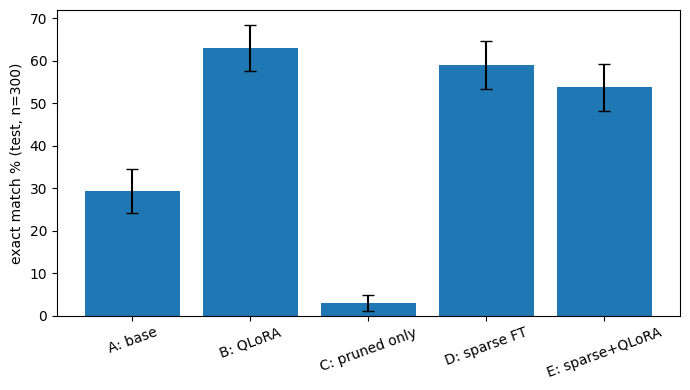

In [56]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

tags = {"A: base": "A_base_zeroshot", "B: QLoRA": "B_qlora",
        "C: pruned only": "C_wanda50_zeroshot", "D: sparse FT": "D_sparse_ft",
        "E: sparse+QLoRA": "E_sparse_qlora"}

rows = {label: score(json.load(open(f"results_{tag}.json"))["raw"], test_list)
        for label, tag in tags.items()}
df = pd.DataFrame(rows).T
n = len(test_list)
df["exact_±95%"] = (196 * np.sqrt(df["exact"] / 100 * (1 - df["exact"] / 100) / n)).round(1)
print(df)

plt.figure(figsize=(7, 4))
plt.bar(df.index, df["exact"], yerr=df["exact_±95%"], capsize=4)
plt.ylabel("exact match % (test, n=300)"); plt.xticks(rotation=20)
plt.tight_layout(); plt.show()

In [57]:
def gb(m): return round(m.get_memory_footprint() / 1e9, 2)

m = load_fp16(); fp16_gb = gb(m); del m
m = AutoModelForCausalLM.from_pretrained(MODEL, quantization_config=bnb,
                                         dtype=torch.float16, device_map="cuda")
q_gb = gb(m); del m; gc.collect(); torch.cuda.empty_cache()

deploy = pd.DataFrame({
    "sparsity %": [0, 0, 50, 50, 50],
    "trainable params": ["0", "1.75% (LoRA)", "0", "all non-zero weights", "1.75% (LoRA)"],
    "weights in memory GB": [fp16_gb, q_gb, fp16_gb, fp16_gb, q_gb],
}, index=df.index)
print(deploy)
!du -sh adapter_B_qlora adapter_E_sparse_qlora pruned_wanda50 sparse_ft_D

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

                 sparsity %      trainable params  weights in memory GB
A: base                   0                     0                  0.99
B: QLoRA                  0          1.75% (LoRA)                  0.45
C: pruned only           50                     0                  0.99
D: sparse FT             50  all non-zero weights                  0.99
E: sparse+QLoRA          50          1.75% (LoRA)                  0.45
17M	adapter_B_qlora
34M	adapter_E_sparse_qlora
954M	pruned_wanda50
954M	sparse_ft_D


In [58]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/drive/MyDrive/sparse_capstone
!cp -r results_*.json adapter_B_qlora adapter_E_sparse_qlora /content/drive/MyDrive/sparse_capstone/

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
